MovieWriter ffmpeg unavailable; using Pillow instead.


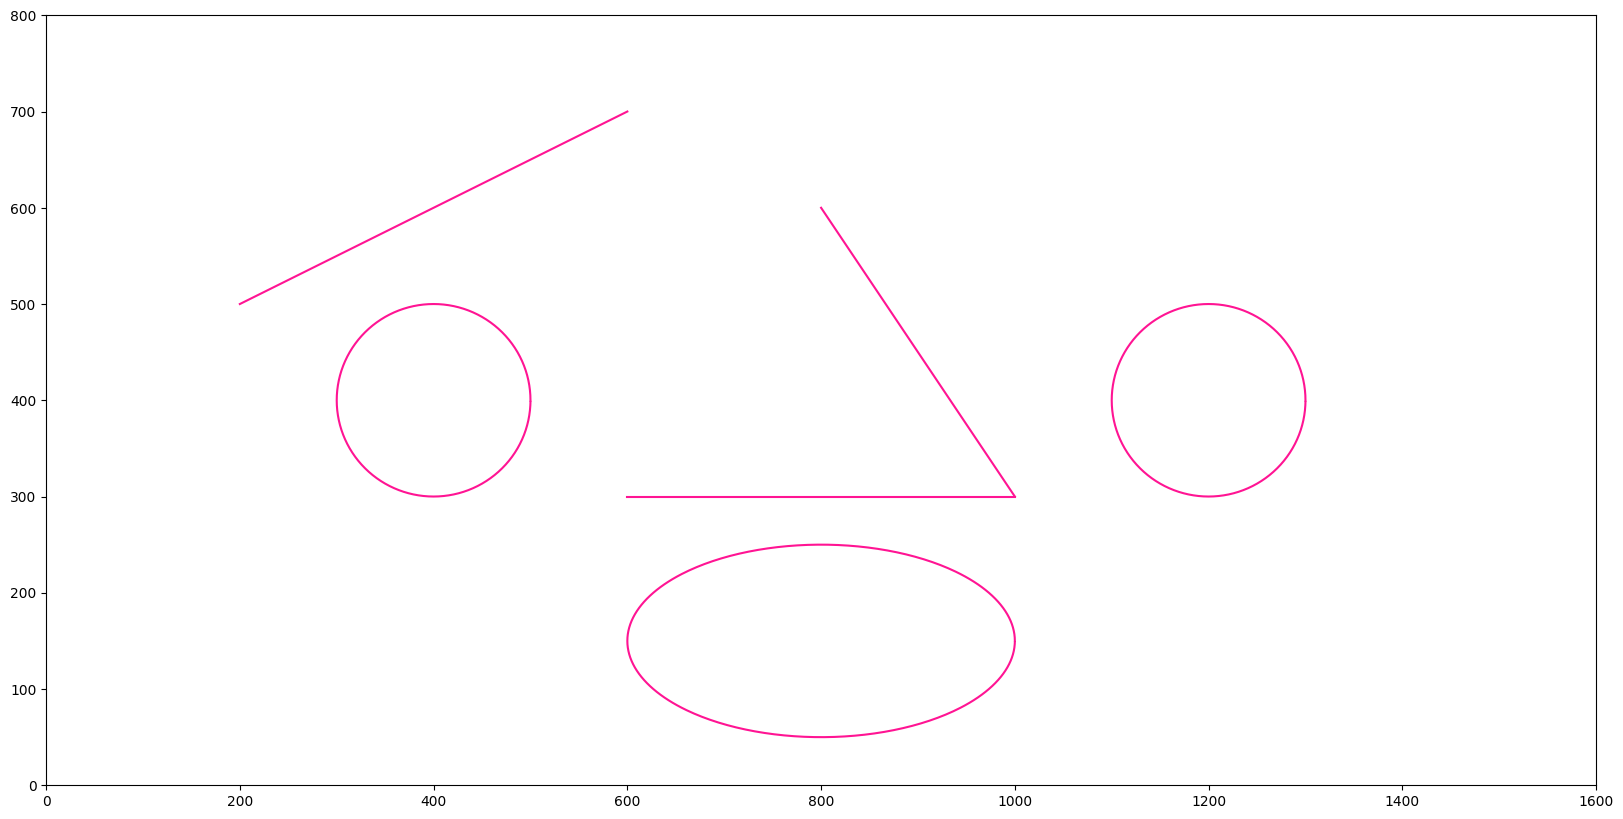

In [76]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import math


class Animation:
    def __init__(self, width, height):
        self.width = width
        self.height = height
        self.circles = {}
        self.lines = {}

    def add_circle(self, name, radius, k, pos, color):
        self.circles.update({name: {"radius": radius, "k": k, "pos": pos, "color": color,  "plot":None}})
        
    def delete_circle(self, name):
        self.circles[name]["plot"][0].set_data(1, 1)
        self.circles.pop(name)
        

        
    def delete_line(self, name):
        self.lines[name]["plot"][0].set_data(1, 1)
        self.lines.pop(name)
        
    def clear(self):
        a = list(self.circles.keys()) 
        for i in a:
            self.delete_circle(i)
        
        a = list(self.lines.keys()) 
        for i in a:
            self.delete_line(i)

    def set_k(self, name, xy, k):
        if xy == "x":
            self.circles[name]["k"][0] = k
        else:
            self.circles[name]["k"][1] = k
            
    def scale_radius(self, name, r):
        self.circles[name]["radius"] += r
            
    def move(self, name, v):
        self.lines[name]["begin"][0] += v[0]
        self.lines[name]["begin"][1] += v[1]
        
        self.lines[name]["end"][0] += v[0]
        self.lines[name]["end"][1] += v[1]


    def add_line(self, name, begin, end, color):
        self.lines.update({name: {"begin": begin, "end": end, "color": color,  "plot":None}})

    def show(self, plot):
        gs = []

        for i in self.circles.keys():
            xdata = []
            ydata = []

            t = self.circles[i]
            for j in range(360):
                xdata.append(math.cos(math.radians(j)) * t["radius"] * t["k"][0] + t["pos"][0])
                ydata.append(math.sin(math.radians(j)) * t["radius"] * t["k"][1] + t["pos"][1])

            if t["plot"] is None:
                t["plot"] = plot.plot(xdata, ydata, c=t["color"])
            else:
                t["plot"][0].set_data(xdata, ydata)
            gs.append(t["plot"][0])

        for i in self.lines.keys():
            t = self.lines[i]

            xdata = [t["begin"][0], t["end"][0]]
            ydata = [t["begin"][1], t["end"][1]]

            if t["plot"] is None:
                t["plot"] = plot.plot(xdata, ydata, c=t["color"])
            else:
                t["plot"][0].set_data(xdata, ydata)
            gs.append(t["plot"][0])


        return tuple(gs)


width = 1600
height = 800

a = Animation(width, height)


#deathstar
a.add_circle("ds1", 200, [1, 1], [400, 450], 'gray')
a.add_circle("ds2", 200, [0.7, 1], [400, 450], 'gray')
a.add_circle("ds3", 200, [0.4, 1], [400, 450], 'gray')
a.add_circle("ds4", 200, [0, 1], [400, 450], 'gray')

a.add_circle("ds5", 60, [1, 1], [450, 550], 'gray')
a.add_circle("ds6", 30, [1, 1], [450, 550], 'gray')
a.add_line("ds7", [200, 450], [600, 450], 'gray')


#planet
a.add_circle("p1", 100, [1, 1], [1200, 600], 'green')


fig = plt.figure(figsize=(20,10))
ax = plt.axes(xlim=(0, width), ylim=(0, height))

ax.set_xlim([0, width])
ax.set_ylim([0, height])


def init():
    a.set_k("c", "y", 0)
    return a.show(ax)


def animate(frame):
    if frame == 80:  
        a.add_line("ld", [450, 550], [600, 575], 'lightgreen')
        
    if frame > 80 and frame < 90:
        a.move("ld", (60, 10))
        
    if frame == 90:
        a.delete_line("ld")
        a.add_circle("fire1", 60, [1, 0.3], [1200, 600], 'red')
        a.add_circle("fire2", 40, [1, 0.6], [1200, 600], 'orange')
        
    if frame > 90 and frame < 120:
        a.scale_radius("fire1", 10)
        a.scale_radius("fire2", 12)
        
        
    if frame == 120:
        a.clear()

        
        
        a.add_circle("a", 100, [1, 1], [400, 400], 'deeppink')

        a.add_circle("b", 100, [1, 1], [1200, 400], 'deeppink')

        a.add_circle("mouse", 100, [2, 1], [800, 150], 'deeppink')

        a.add_line("a", [200, 500], [600, 700], 'deeppink')



        a.add_line("c", [800, 600], [1000, 300], 'deeppink')

        a.add_line("d", [1000, 300], [600, 300], 'deeppink')
        

        
        

    return a.show(ax)

anim = animation.FuncAnimation(fig, animate,  frames=200, interval=1 )
anim.save(filename = "sasa.gif")